# KPI 2 – Time spent on each step

**Project:** Vanguard A/B test · **Owner:** Juliana
*(Completion rate and error rate are analysed by the other team members.)*

**Question:** do clients using the **new design (Test)** spend less time on each step of the online process than clients using the **old design (Control)**?

**Data:** Merged file `vanguard_master_merged` (web data + experiment roster + client profiles).

| Day | Goal | Section |
|---|---|---|
| **Day 3** | KPI: **average time spent on each step**, Test vs Control | 3 |
| **Day 4** | Hypothesis test: is the new design significantly **faster** on each step? | 4 |
| | Conclusion | 5 |

## 0. Setup

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

STEP_ORDER = {"start": 0, "step_1": 1, "step_2": 2, "step_3": 3, "confirm": 4}
STEPS = list(STEP_ORDER)
GROUPS = ["Control", "Test"]
MAX_SECONDS = 30 * 60        # a gap longer than 30 min = client left / idle, not "time on the step"

pd.set_option("display.max_columns", None)

In [3]:
# chart style – one colour per group in every chart (validated for colour-blind safety)
COLORS = {"Control": "#eb6834", "Test": "#2a78d6"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})

def grouped_bars(table, title, ylabel, fmt="{:.0f}", percent=False, save=None, figsize=(8, 4)):
    """Grouped bars: index = categories, columns = Control / Test."""
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(table.index)); width = 0.38
    for i, g in enumerate(GROUPS):
        bars = ax.bar(x + (i - 0.5) * (width + 0.02), table[g], width=width, color=COLORS[g], label=g)
        for b, v in zip(bars, table[g]):
            ax.annotate(f"{v:.0%}" if percent else fmt.format(v), (b.get_x() + b.get_width() / 2, b.get_height()),
                        ha="center", va="bottom", fontsize=8, color="#3d3d3a", xytext=(0, 2), textcoords="offset points")
    ax.set_xticks(x); ax.set_xticklabels(table.index)
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel)
    if percent: ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, table[GROUPS].to_numpy().max() * 1.12)
    ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))
    if save: plt.savefig(FIG_DIR / save, dpi=150, bbox_inches="tight")
    return ax

## 1. Load Merged file

In [4]:
# works with the .csv or the .zip merged file sent (put it in data/clean/)
csv_path, zip_path = CLEAN_DIR / "vanguard_master_merged.csv", CLEAN_DIR / "vanguard_master_merged.zip"
DATA_FILE = csv_path if csv_path.exists() else zip_path

df_all = pd.read_csv(DATA_FILE, parse_dates=["date_time"], low_memory=False)
print(f"{DATA_FILE.name}: {df_all.shape[0]:,} rows x {df_all.shape[1]} columns")
df_all.head()

vanguard_master_merged.csv: 744,641 rows x 14 columns


,client_id,visitor_id,visit_id,process_step,date_time,variation,clnt_tenure_yr,clnt_tenure_mnth,clnt_age,gendr,num_accts,bal,calls_6_mnth,logons_6_mnth
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,Test,5.0,64.0,79.0,U,2.0,189023.86,1.0,4.0


## 2. Prepare the data for time analysis

Merged file keeps **all** web actions, including clients who were **not in the experiment** (`variation` is empty). For the A/B comparison:

1. **Keep only Test and Control clients.**
2. **Make each visit unique:** the same `visit_id` is used by different clients, so a visit = `client_id` + `visit_id`.
3. **Sort each visit by time.** When two actions share the same second, the earlier step goes first.
4. **Time on a step** = seconds from this action until the **next action in the same visit**. The last action of a visit has no "next", so it has no time.
5. **Gaps longer than 30 minutes** mean the client left the page. They are flagged and left out of the averages, but kept in the data.

In [5]:
print("Rows by variation (NaN = not in the experiment):")
print(df_all["variation"].value_counts(dropna=False).to_dict())

df = df_all[df_all["variation"].isin(GROUPS)].copy()
df["visit_key"] = df["client_id"].astype(str) + "_" + df["visit_id"].astype(str)
df["step_num"] = df["process_step"].map(STEP_ORDER)
df = df.sort_values(["visit_key", "date_time", "step_num"]).reset_index(drop=True)

g = df.groupby("visit_key", sort=False)
df["step_seconds"] = (g["date_time"].shift(-1) - df["date_time"]).dt.total_seconds()
df["valid_time"] = df["step_seconds"].between(0, MAX_SECONDS)

print(f"\nExperiment actions : {len(df):,}  |  clients: {df['client_id'].nunique():,}  |  visits: {df['visit_key'].nunique():,}")
print(f"Actions with a time (not last in visit): {df['step_seconds'].notna().sum():,}")
print(f"Gaps > 30 min excluded                  : {(df['step_seconds'] > MAX_SECONDS).sum():,} "
      f"({(df['step_seconds'] > MAX_SECONDS).mean():.2%} of actions)")

Rows by variation (NaN = not in the experiment):
{nan: 427406, 'Test': 176699, 'Control': 140536}

Experiment actions : 317,235  |  clients: 50,500  |  visits: 69,447
Actions with a time (not last in visit): 247,788
Gaps > 30 min excluded                  : 349 (0.11% of actions)


In [6]:
# distribution check: why we need the 30-min rule
df.loc[df["step_seconds"].notna(), "step_seconds"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1)

count    247788.0
mean         83.9
std         214.0
min           0.0
50%          36.0
75%          82.0
90%         177.0
95%         299.0
99%         962.0
max       40235.0
Name: step_seconds, dtype: float64

Half of all steps take **under ~40 s**, but a few gaps last **hours** (the client left and came back). Those would distort the average, so they're excluded.

`confirm` is the **last page** of the process. The time *after* it isn't time spent completing the process, so it's left out of time per step.

In [7]:
t = df[df["valid_time"] & (df["process_step"] != "confirm")]
print(f"Step times used in the KPI: {len(t):,}")

Step times used in the KPI: 241,587


## 3. Day 3 – KPI: average time spent on each step

In [8]:
avg = (t.pivot_table(index="process_step", columns="variation", values="step_seconds", aggfunc="mean")
        .reindex(STEPS[:-1])[GROUPS])

kpi = avg.copy()
kpi["Difference (s)"] = kpi["Test"] - kpi["Control"]
kpi["Difference (%)"] = kpi["Test"] / kpi["Control"] - 1
kpi["Faster"] = kpi["Difference (s)"].apply(lambda d: "Test" if d < 0 else "Control")
kpi.style.format({"Control": "{:.1f}", "Test": "{:.1f}", "Difference (s)": "{:+.1f}", "Difference (%)": "{:+.1%}"})

variation,Control,Test,Difference (s),Difference (%),Faster
process_step,,,,,
start,60.9,56.3,-4.6,-7.6%,Test
step_1,47.5,58.4,+11.0,+23.1%,Control
step_2,90.0,88.1,-1.9,-2.1%,Test
step_3,132.9,124.8,-8.1,-6.1%,Test


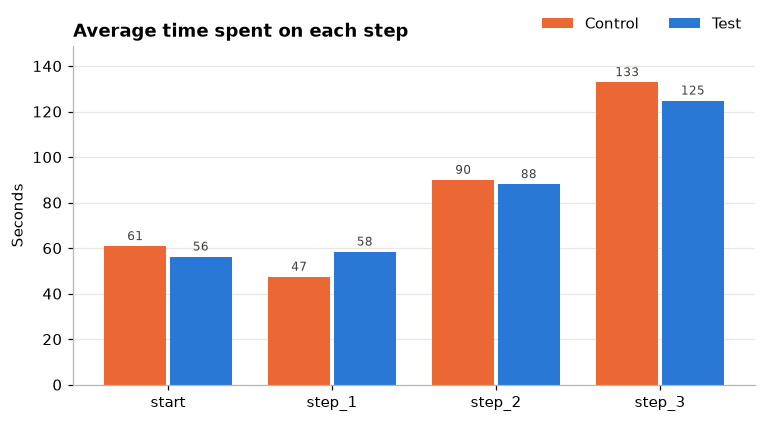

In [9]:
grouped_bars(avg, "Average time spent on each step", "Seconds", save="kpi_avg_time_per_step.png");

**Day 3 result:** with the new design, clients spend **less time** on `start`, `step_2` and `step_3`, but **more time on `step_1`** (about 11 s more, +23%).

## 4. Day 4 – Hypothesis test: is the new design faster?

The business question is whether the new design makes clients **faster**, not just *different*. So we use a **one-sided two-sample t-test** for each step.

- **H0 (null hypothesis):** the average time on the step with the new design is **equal to or longer than** the old design (Test ≥ Control → *not faster*)
- **H1 (alternative hypothesis):** the average time on the step with the new design is **shorter** (Test < Control → *faster*)
- **Significance level α = 0.05**: if p-value < 0.05 → reject H0 → the new design is significantly faster on that step

In Python: `stats.ttest_ind(test, control, equal_var=False, alternative="less")`
- `alternative="less"` → tests if the **Test** average is **less** (shorter) than the Control average
- **The order matters:** Test first, Control second

**Prerequisites**
- Two **independent** groups: each client is either in Test or in Control.
- Large samples (tens of thousands of step times per group), so the t-test works even though time data is skewed. The averages of large samples are close to normally distributed (Central Limit Theorem).
- The groups have different sizes and spreads → Welch's version of the t-test (`equal_var=False`).

In [10]:
alpha = 0.05
rows = []
for s in STEPS[:-1]:
    control = t.loc[(t["process_step"] == s) & (t["variation"] == "Control"), "step_seconds"]
    test = t.loc[(t["process_step"] == s) & (t["variation"] == "Test"), "step_seconds"]

    # one-sided: H1 = Test average < Control average (new design is faster)
    t_stat, p = stats.ttest_ind(test, control, equal_var=False, alternative="less")

    rows.append({"step": s, "Control avg (s)": control.mean(), "Test avg (s)": test.mean(),
                 "difference (s)": test.mean() - control.mean(), "t-statistic": t_stat, "p-value": p,
                 "Result": "Reject H0 – Test is faster" if p < alpha else "Fail to reject H0 – Test is not faster"})

results = pd.DataFrame(rows).set_index("step")
results.style.format({"Control avg (s)": "{:.1f}", "Test avg (s)": "{:.1f}", "difference (s)": "{:+.1f}",
                      "t-statistic": "{:.2f}", "p-value": "{:.4f}"})

,Control avg (s),Test avg (s),difference (s),t-statistic,p-value,Result
step,,,,,,
start,60.9,56.3,-4.6,-4.66,0.0000,Reject H0 – Test is faster
step_1,47.5,58.4,+11.0,12.49,1.0000,Fail to reject H0 – Test is not faster
step_2,90.0,88.1,-1.9,-1.96,0.0251,Reject H0 – Test is faster
step_3,132.9,124.8,-8.1,-4.54,0.0000,Reject H0 – Test is faster


**How to read it**
- A **negative t-statistic** means the Test average is **lower** (faster) than Control. A **positive** one means Test is slower.
- **p-value < 0.05** → reject H0: the new design is **significantly faster** on that step.
- On `step_1` the p-value is ≈ 1.00. Test is **slower** there, so there's no evidence at all that it's faster.

## 5. Day 4 conclusion: is the new design faster?

| Step | Control avg | Test avg | p-value (one-sided) | Is the new design faster? |
|---|---|---|---|---|
| `start` | 60.9 s | 56.3 s | < 0.001 | ✅ **Yes**, significantly faster |
| `step_1` | 47.5 s | 58.4 s | ≈ 1.00 | ❌ **No**, it's **slower** (+11 s) |
| `step_2` | 90.0 s | 88.1 s | ≈ 0.025 | ✅ **Yes**, slightly faster (−2 s) |
| `step_3` | 132.9 s | 124.8 s | < 0.001 | ✅ **Yes**, significantly faster |

- **The new design is significantly faster on 3 of the 4 steps** (`start`, `step_2`, `step_3`).
- **`step_1` is the exception:** clients spend about **11 s more** there with the new design. This is the weak point of the redesign and should be reviewed. Check it against the error-rate findings: if many Test clients also go back from step_1 to start, both KPIs point to the same problem.

**Note on `step_2`:** with the one-sided test the difference is significant (p ≈ 0.025), but it's only about **2 seconds**, too small to matter for clients. With a two-sided ("different?") test it was just above 0.05. The one-sided test fits the business question better, but this result is borderline.

**Considerations**
- Time is measured until the **next action** in the logs, so it includes reading, typing and short pauses.
- Pauses > 30 min (0.1% of actions) are excluded as "client left".
- With this many clients even small differences become significant, so look at the **size** of the difference in seconds too, not only the p-value.

In [11]:
# Save a Tableau-ready file 
TABLEAU_DIR = PROJECT_ROOT / "data" / "tableau"
TABLEAU_DIR.mkdir(exist_ok=True)

export = df[["client_id", "visit_key", "process_step", "step_num", "date_time", "step_seconds"]].copy()
export["is_error"] = (df["step_num"] < df.groupby("visit_key")["step_num"].shift()).astype(int)   # went back a step
export["valid_time"] = (df["valid_time"] & (df["process_step"] != "confirm")).astype(int)         # 1 = time is used
export.loc[export["valid_time"] == 0, "step_seconds"] = None    # blank → Tableau's AVG() ignores it
export["month"] = df["date_time"].dt.to_period("M").dt.to_timestamp()

cols = ["client_id", "visit_key", "process_step", "step_num", "date_time",
        "is_error", "step_seconds", "valid_time", "month"]
export[cols].to_csv(TABLEAU_DIR / "tableau_steps.csv", index=False)
print(f"tableau_steps.csv saved: {len(export):,} rows")

tableau_steps.csv saved: 317,235 rows
